In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df = sns.load_dataset("titanic")
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [12]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


<div dir="rtl" align="right">

# بررسی ساختار اولیه داده
## ساختار کلی
- تعداد سطر ها(تعداد مسافر ها) : 891
- تعداد ستون ها: 15
- حجم دیتا: 100.4KB

## دیتا های گمشده (missing values)
- age : 177 missing values
- embarked: 2 missing values
- embark_town: 2 missing values
- deck: 688 missing values



</div>

In [13]:
df.describe().round(2)


,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


<div dir="rtl" align="right">

# با این دستور تعداد مقدایر گمشده مربوط به هر ستون رو پیدا کردیم





</div>

In [14]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

<div dir="rtl" align="right">

## تعداد مقادیر یکتا در هر ستون




</div>

In [15]:
df.nunique()

survived         2
pclass           3
sex              2
age             88
sibsp            7
parch            7
fare           248
embarked         3
class            3
who              3
adult_male       2
deck             7
embark_town      3
alive            2
alone            2
dtype: int64

<div dir="rtl" align="right">

## به صورت مجزا ستون سن مورد بررسی قرار گرفت





</div>


In [16]:
df['age'].info()

<class 'pandas.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: age
Non-Null Count  Dtype  
--------------  -----  
714 non-null    float64
dtypes: float64(1)
memory usage: 7.1 KB


In [17]:
df['age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64

In [18]:
df['age'].isna().sum()

np.int64(177)

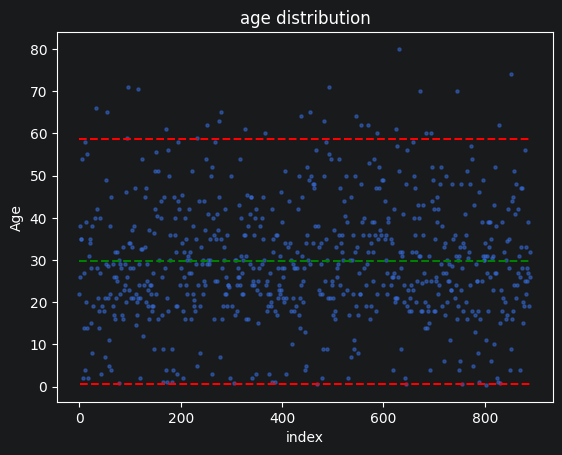

In [19]:
plt.scatter(df.index, df['age'],s=5,alpha=0.5)

plt.xlabel("index")
plt.ylabel("Age")
plt.title("age distribution")
mean = df['age'].mean()

plt.hlines(mean, 0,890, color="g", linestyle="dashed", label="Mean")

std = df['age'].std()
upper_bond = mean + 2*std
lower_bond = mean - 2*std

plt.hlines(upper_bond,0,890,color="r",linestyle="dashed", label="Upper_Bond")
plt.hlines(lower_bond,0.890,890,color="r",linestyle="dashed", label="Lower_Bond")

In [20]:
outlier = (df['age'] > upper_bond) | (df['age'] < lower_bond)
outlier.sum()

np.int64(29)

In [21]:
outliers_idx = np.where((df['age'] > upper_bond) |(df['age'] < lower_bond))
outliers_idx

(array([ 33,  54,  94,  96, 116, 170, 232, 252, 275, 280, 326, 366, 438,
        456, 483, 493, 545, 555, 570, 587, 625, 630, 672, 684, 694, 745,
        803, 829, 851]),)

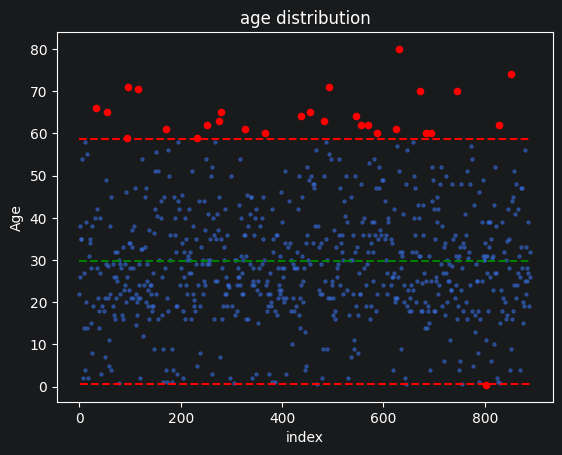

In [22]:
plt.scatter(df.index, df['age'],s=5,alpha=0.5)

plt.xlabel("index")
plt.ylabel("Age")
plt.title("age distribution")
mean = df['age'].mean()

plt.hlines(mean, 0,890, color="g", linestyle="dashed", label="Mean")

std = df['age'].std()
upper_bond = mean + 2*std
lower_bond = mean - 2*std

plt.hlines(upper_bond,0,890,color="r",linestyle="dashed", label="Upper_Bond")
plt.hlines(lower_bond,0.890,890,color="r",linestyle="dashed", label="Lower_Bond")
plt.scatter(
    df.index[outlier],
    df['age'][outlier],
    color='red',
    s=20,
    label='Outliers',
)

In [23]:
df['age'].value_counts()

age
24.00    30
22.00    27
18.00    26
28.00    25
19.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64

Text(0, 0.5, 'Frequency')

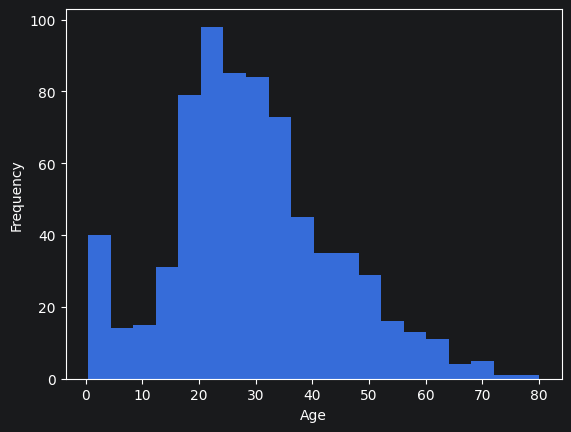

In [24]:
plt.hist(df['age'], bins=20)
plt.xlabel("Age")
plt.ylabel("Frequency")

In [25]:
df['fare'].info()


<class 'pandas.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: fare
Non-Null Count  Dtype  
--------------  -----  
891 non-null    float64
dtypes: float64(1)
memory usage: 7.1 KB


In [26]:
df['fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

In [27]:
df['fare'].isna().sum()

np.int64(0)

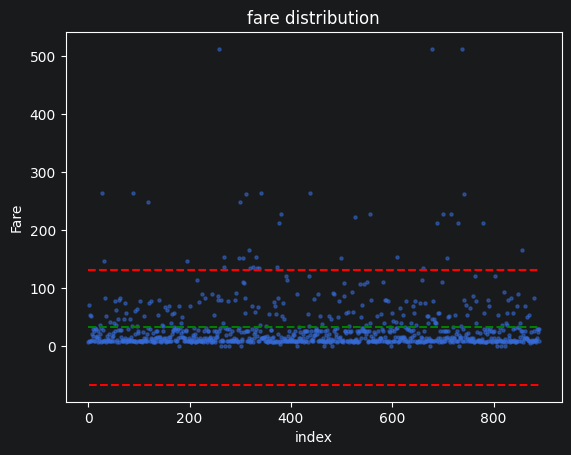

In [28]:
plt.scatter(df.index, df['fare'],s=5,alpha=0.5)

plt.xlabel("index")
plt.ylabel("Fare")
plt.title("fare distribution")
mean = df['fare'].mean()

plt.hlines(mean, 0,890, color="g", linestyle="dashed", label="Mean")

std = df['fare'].std()
upper_bond = mean + 2*std
lower_bond = mean - 2*std

plt.hlines(upper_bond,0,890,color="r",linestyle="dashed", label="Upper_Bond")
plt.hlines(lower_bond,0.890,890,color="r",linestyle="dashed", label="Lower_Bond")

In [29]:
outlier = (df['fare'] > upper_bond) | (df['fare'] < lower_bond)
outlier.sum()


np.int64(38)

In [30]:
outliers_idx = np.where((df['fare'] > upper_bond) |(df['fare'] < lower_bond))
outliers_idx

(array([ 27,  31,  88, 118, 195, 258, 268, 269, 297, 299, 305, 311, 318,
        319, 325, 332, 334, 337, 341, 373, 377, 380, 438, 498, 527, 557,
        609, 660, 679, 689, 700, 708, 716, 730, 737, 742, 779, 856]),)

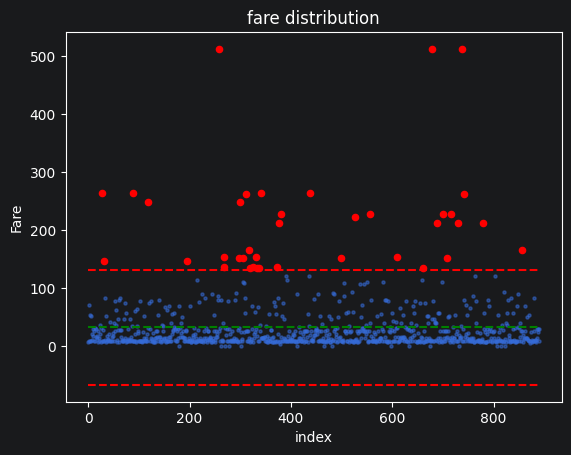

In [37]:
plt.scatter(df.index, df['fare'],s=5,alpha=0.5)

plt.xlabel("index")
plt.ylabel("Fare")
plt.title("fare distribution")
mean = df['fare'].mean()

plt.hlines(mean, 0,890, color="g", linestyle="dashed", label="Mean")

std = df['fare'].std()
upper_bond = mean + 2*std
lower_bond = mean - 2*std

plt.hlines(upper_bond,0,890,color="r",linestyle="dashed", label="Upper_Bond")
plt.hlines(lower_bond, 0, 890, color="r",
           linestyle="dashed", label="Lower_Bond")
plt.scatter(
    df.index[outlier],
    df['fare'][outlier],
    color='red',
    s=20,
    label='Outliers',
)

In [32]:
df['fare'].value_counts()


fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64

Text(0.5, 1.0, 'fare distribution')

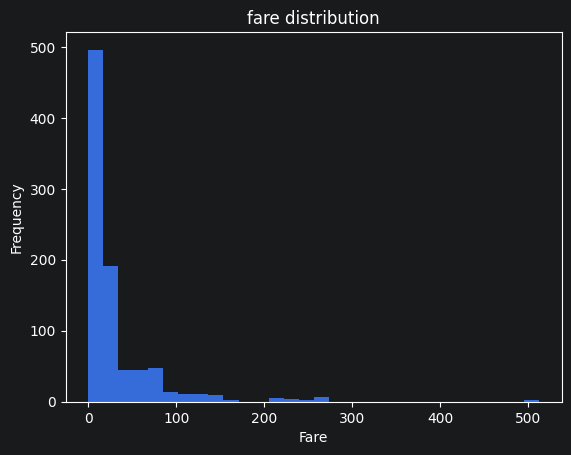

In [34]:
plt.hist(df['fare'], bins=30)
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.title("fare distribution")


In [39]:
df['survived'].info

<bound method Series.info of 0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: survived, Length: 891, dtype: int64>

In [40]:
df['survived'].describe


<bound method NDFrame.describe of 0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: survived, Length: 891, dtype: int64>

In [43]:
df['survived'].isna().sum()

np.int64(0)

In [41]:
df['survived'].unique()

array([0, 1])

In [44]:
df['survived'].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [ ]:
df['survived'].value_counts()

In [47]:
survived_counts = df['survived'].value_counts()

survived_percent = (survived_count/len(df))*100

print(survived_percent)

survived
0    61.616162
1    38.383838
Name: count, dtype: float64


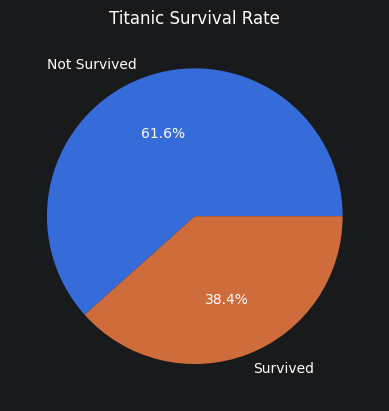

In [49]:
plt.pie(
    survived_percent,
    labels=['Not Survived', 'Survived'],
    autopct='%1.1f%%'
)

plt.title('Titanic Survival Rate')
plt.show()

In [53]:
df['pclass'].describe()

count    891.000000
mean       2.308642
std        0.836071
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        3.000000
Name: pclass, dtype: float64

In [56]:
df['pclass'].isna().sum()

np.int64(0)

In [58]:
df['pclass'].unique()

array([3, 1, 2])

In [54]:
df['pclass'].value_counts()

pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [55]:
pclass_count = df['pclass'].value_counts()
pclass_percent = (pclass_count/len(df))*100

print(pclass_percent)

pclass
3    55.106622
1    24.242424
2    20.650954
Name: count, dtype: float64


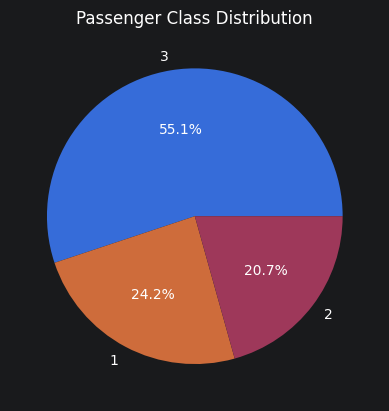

In [57]:
pclass_count = df['pclass'].value_counts()

plt.pie(
    pclass_count,
    labels=pclass_count.index,
    autopct='%1.1f%%'
)

plt.title('Passenger Class Distribution')
plt.show()

In [62]:
df['sex'].value_counts()

sex
male      577
female    314
Name: count, dtype: int64

In [65]:
df['sex'].unique()

<ArrowStringArray>
['male', 'female']
Length: 2, dtype: str

In [63]:
sex_count = df['sex'].value_counts()
sex_percent = (sex_count / len(df))*100

print(sex_percent)

sex
male      64.758698
female    35.241302
Name: count, dtype: float64


In [64]:
df['sex'].isna().sum()

np.int64(0)

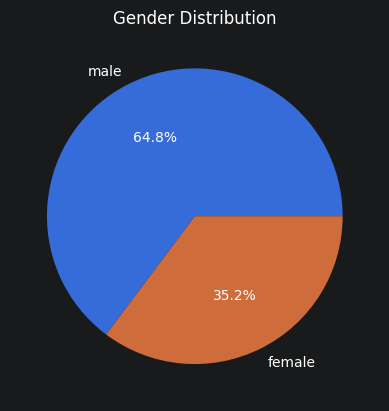

In [66]:
sex_count = df['sex'].value_counts()

plt.pie(
    sex_count,
    labels=sex_count.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')
plt.show()